# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032 |

## Deskripsi Singkat
Membangun model ANN (MLPClassifier) untuk klasifikasi, mengeksplorasi fungsi aktivasi, arsitektur, dan evaluasi.

## 1. Persiapan dan Import Library

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 2. Load Dataset & Eksplorasi Awal

In [36]:
df = pd.read_csv('data/ann.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [37]:
print(df.dtypes)
print(df.isnull().sum())

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
Mo

Churn
No     5174
Yes    1869
Name: count, dtype: int64


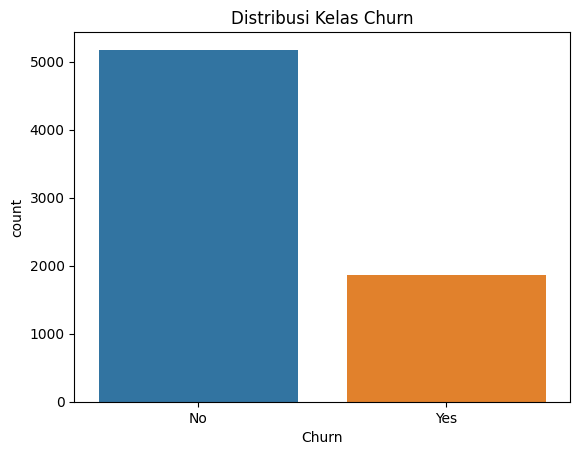

In [38]:
print(df['Churn'].value_counts())
sns.countplot(x='Churn', data=df, hue = 'Churn')
plt.title('Distribusi Kelas Churn')
plt.show()

## 3. Preprocessing

In [39]:

df = df.drop(columns=['customerID'])
print('customerID dropped, shape:', df.shape)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


customerID dropped, shape: (7043, 20)


In [40]:

le = LabelEncoder()
df['Churn'] = le.fit_transform(df['Churn'])
print('Mapping:', list(le.classes_), '->', list(le.transform(le.classes_)))

Mapping: ['No', 'Yes'] -> [np.int64(0), np.int64(1)]


In [41]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X = pd.get_dummies(X, drop_first=True)
print('Jumlah fitur setelah encoding:', X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}')

Jumlah fitur setelah encoding: 30
Train size: 5634, Test size: 1409


In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Eksperimen Model - Baseline

In [43]:
baseline_clf = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', max_iter=300, random_state=42)
baseline_clf.fit(X_train_scaled, y_train)
print('Accuracy baseline:', baseline_clf.score(X_test_scaled, y_test))

ValueError: Input X contains NaN.
MLPClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
y_pred_baseline = baseline_clf.predict(X_test_scaled)

Prediksi baseline (10 pertama): [0 1 0 0 0 1 1 0 0 0]
Aktual (10 pertama): [0 0 0 0 0 0 0 0 0 1]


## 5. Eksperimen Fungsi Aktivasi

In [ ]:
activations = ['relu', 'tanh', 'logistic']
act_results = []
for act in activations:
    clf = MLPClassifier(hidden_layer_sizes=(10,), activation=act, max_iter=300, random_state=42)
    clf.fit(X_train_scaled, y_train)
    acc = clf.score(X_test_scaled, y_test)
    act_results.append({'activation': act, 'accuracy': acc})
    print(f'Activation {act}: test accuracy = {acc:.4f}')

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation relu: test accuracy = 0.7956


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation tanh: test accuracy = 0.7906
Activation logistic: test accuracy = 0.7906


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
act_df = pd.DataFrame(act_results)
print(act_df)

Ringkasan aktivasi:
  activation  accuracy
0       relu  0.795600
1       tanh  0.790632
2   logistic  0.790632


## 6. Eksperimen Ukuran Arsitektur (Regularisasi)

In [ ]:
best_act = act_df.loc[act_df['accuracy'].idxmax(), 'activation']
print('best activation', best_act)

arch_sizes = [(2,), (5,), (10,), (50,), (100, 50)]
arch_results = []
for size in arch_sizes:
    clf = MLPClassifier(hidden_layer_sizes=size, activation=best_act, max_iter=300, random_state=42)
    clf.fit(X_train_scaled, y_train)
    train_acc = clf.score(X_train_scaled, y_train)
    test_acc = clf.score(X_test_scaled, y_test)
    arch_results.append({'layers': size, 'train_acc': train_acc, 'test_acc': test_acc})
    print(f'Size {size} -> train: {train_acc:.4f}, test: {test_acc:.4f}')

Aktivasi terbaik: relu
Size (2,) -> train: 0.8060, test: 0.7942
Size (5,) -> train: 0.8140, test: 0.7942


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Size (10,) -> train: 0.8193, test: 0.7956
Size (50,) -> train: 0.8408, test: 0.7871
Size (100, 50) -> train: 0.9528, test: 0.7459


In [ ]:
arch_df = pd.DataFrame(arch_results)
print(arch_df)

Ringkasan arsitektur:
      layers  train_acc  test_acc
0       (2,)   0.805999  0.794180
1       (5,)   0.813987  0.794180
2      (10,)   0.819311  0.795600
3      (50,)   0.840788  0.787083
4  (100, 50)   0.952787  0.745919


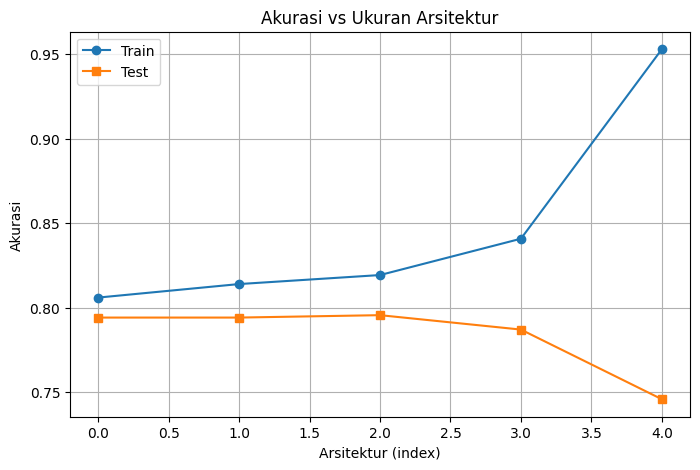

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(arch_df.index, arch_df['train_acc'], marker='o', label='Train')
plt.plot(arch_df.index, arch_df['test_acc'], marker='s', label='Test')
plt.title('Akurasi vs Ukuran Arsitektur')
plt.xlabel('Arsitektur (index)')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

## 7. Evaluasi Model Terbaik

In [ ]:
best_idx = arch_df['test_acc'].idxmax()
best_cfg = arch_results[best_idx]
best_clf = MLPClassifier(hidden_layer_sizes=best_cfg['layers'], activation=best_act, max_iter=300, random_state=42)
best_clf.fit(X_train_scaled, y_train)
y_pred_best = best_clf.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred_best)
prec = precision_score(y_test, y_pred_best, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_best, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_best, average='weighted', zero_division=0)

metrics_df = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'], 'Value': [acc, prec, rec, f1]})
print('best metrik model:')
print(metrics_df)

Metrik model terbaik:
      Metric     Value
0   Accuracy  0.795600
1  Precision  0.787847
2     Recall  0.795600
3   F1-Score  0.790469


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


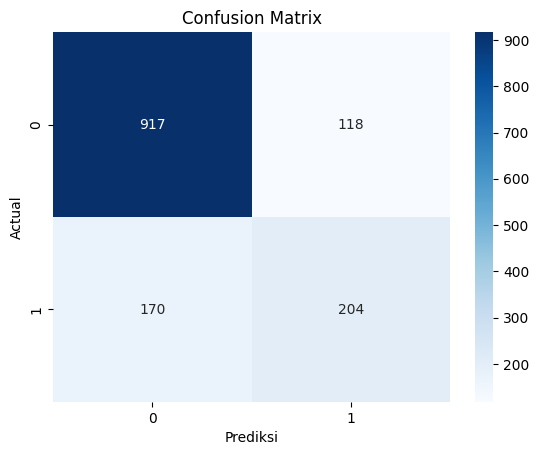

In [ ]:
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Actual')
plt.show()

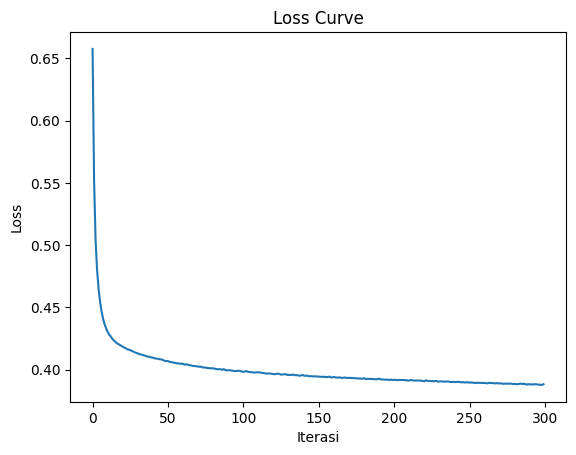

Loss curve selesai


In [ ]:
plt.plot(best_clf.loss_curve_)
plt.title('Loss Curve')
plt.xlabel('Iterasi')
plt.ylabel('Loss')
plt.show()

## 8. Analisis


#Pengujian fungsi aktivasi pada model menunjukkan perbedaan hasil yang jelas.
-ReLU memberikan akurasi tertinggi dan waktu pelatihan paling cepat. Sifatnya yang linier pada area positif membuat turunannya selalu konstan, sehingga terhindar dari masalah penurunan gradien secara drastis. Pembaruan bobot berjalan lancar dari lapisan belakang hingga lapisan depan.

-Tanh berada di posisi menengah. Walau titik tengahnya berada di angka nol yang membantu kestabilan pembaruan bobot, fungsi ini tetap mengalami kejenuhan saat input terlalu besar atau kecil. Akibatnya nilai gradien mengecil dan proses pelatihan menjadi lambat.

-Logistic atau Sigmoid menghasilkan kinerja paling rendah dan butuh iterasi paling banyak. Fungsi ini memetakan nilai ke rentang nol sampai satu dengan nilai turunan maksimum yang sangat kecil. Hal ini membuat gradien menyusut dengan cepat saat proses perambatan balik, sehingga pembaruan bobot di lapisan awal menjadi sangat lambat.

#Pengaruh Ukuran Arsitektur dan Overfitting.

Penambahan jumlah neuron dan lapisan tersembunyi meningkatkan kemampuan model dalam memahami pola data yang rumit. Namun, penambahan berlebihan justru memicu masalah, Model mulai mengalami overfitting saat arsitektur dibuat terlalu besar dibanding kompleksitas data. Model tidak lagi mempelajari pola umum, melainkan menghafal detail dan gangguan pada data latih. lalu tanda overfitting terlihat jelas pada perbandingan grafik akurasi data latih dan data uji. Akurasi data latih terus meningkat tinggi mendekati seratus persen, sedangkan akurasi data uji sempat naik lalu mendatar atau justru menurun. Perbedaan atau jarak yang makin lebar antara kedua garis akurasi tersebut merupakan petunjuk utama terjadinya overfitting.

#Kurva Loss dan Konvergensi

Model dikatakan sudah konvergen jika kurva penurunan kesalahan atau loss curve sudah mendatar di iterasi akhir. Ini menandakan bobot model telah mencapai titik yang stabil, Jika kurva loss masih menurun tajam saat batas maksimum iterasi tercapai, langkah yang perlu dilakukan antara lain:

1. Menambah batas maksimum iterasi agar algoritma pelatihan punya cukup waktu untuk mencapai kondisi stabil
2. Mengubah laju pembelajaran menjadi adaptif agar penyesuaian bobot berjalan lebih fleksibel
3. Mengaktifkan fitur penghentian dini agar proses pelatihan berhenti secara otomatis ketika performa pada data validasi tidak lagi meningkat



## 9. Kesimpulan & Saran


Kesimpulan

1. ReLU merupakan fungsi aktivasi paling efektif karena mampu mempercepat pelatihan dan menghindari masalah penyusutan gradien.
2. Arsitektur model yang terlalu besar menyebabkan overfitting, yang terlihat dari jarak akurasi yang lebar antara data latih dan data uji.
3. Kurva loss penting dipantau untuk memastikan pelatihan tidak berhenti sebelum mencapai hasil terbaik.

Saran

1. Menerapkan regularisasi L2 untuk membatasi ukuran bobot agar model tidak mudah overfitting.
2. Mencoba metode optimasi lain seperti Stochastic Gradient Descent dengan pengaturan laju pembelajaran yang disesuaikan.
3. Melakukan pencarian parameter terbaik secara otomatis menggunakan Grid Search untuk menentukan arsitektur dan laju pembelajaran yang paling tepat.
4. Membandingkan performa model ini dengan algoritma pembanding lain seperti Random Forest atau Gradient Boosting.